# Анализ данных Himalayan Climber Data

Задание:
1. Проверьте пропуски ячеек.
2. Постройте таблицу описательных статистик.
3. Сравните успешные восхождения по возрасту в боксплоте.
4. Постройте матрицу корреляций.
5. Постройте логистическую регрессию (логит функцию) по удачным восхождениям.
6. Постройте ROC кривую и выведите AUC.
7. Постройте матрицу ошибок.
8. По всем пунктам сделайте выводы.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
%matplotlib inline

## Загрузка данных

In [2]:
df = pd.read_csv("climbers_sub.csv")
df.shape

(2076, 25)

In [3]:
df.head()

,rownames,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,...,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres,count,height_metres,first_ascent_year
0,1,AMAD81101,AMAD81101-03,AMAD,Ama Dablam,1981,Spring,M,28,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
1,2,AMAD81101,AMAD81101-04,AMAD,Ama Dablam,1981,Spring,M,27,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
2,3,AMAD81101,AMAD81101-02,AMAD,Ama Dablam,1981,Spring,M,35,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
3,4,AMAD81101,AMAD81101-05,AMAD,Ama Dablam,1981,Spring,M,37,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
4,5,AMAD81101,AMAD81101-06,AMAD,Ama Dablam,1981,Spring,M,43,France,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2076 entries, 0 to 2075
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rownames              2076 non-null   int64  
 1   expedition_id         2076 non-null   object 
 2   member_id             2076 non-null   object 
 3   peak_id               2076 non-null   object 
 4   peak_name             2076 non-null   object 
 5   year                  2076 non-null   int64  
 6   season                2076 non-null   object 
 7   sex                   2076 non-null   object 
 8   age                   2076 non-null   int64  
 9   citizenship           2076 non-null   object 
 10  expedition_role       2075 non-null   object 
 11  hired                 2076 non-null   bool   
 12  highpoint_metres      1483 non-null   float64
 13  success               2076 non-null   bool   
 14  solo                  2076 non-null   bool   
 15  oxygen_used          

## 1. Проверка пропусков ячеек

In [5]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
miss_df = pd.DataFrame({"Пропуски": missing, "% от общего": missing_pct})
miss_df[miss_df["Пропуски"] > 0]

,Пропуски,% от общего
injury_height_metres,2062,99.33
death_cause,2057,99.08
death_height_metres,2057,99.08
injury_type,2052,98.84
highpoint_metres,593,28.56
first_ascent_year,7,0.34
expedition_role,1,0.05


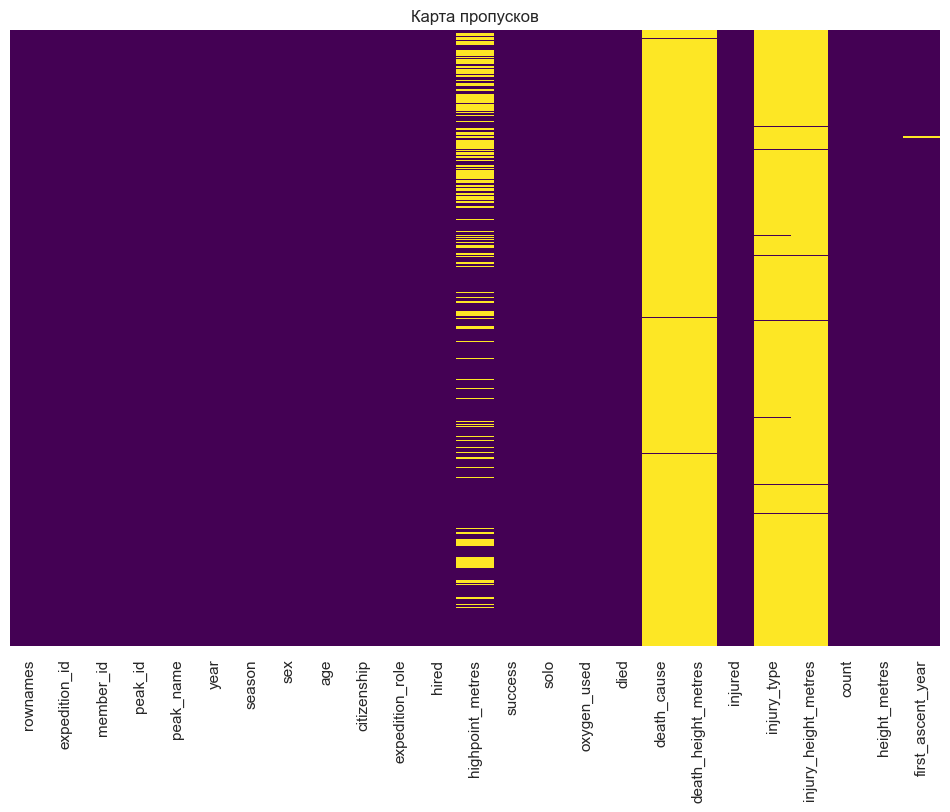

In [6]:
# Визуализация пропусков
plt.figure(figsize=(12, 8))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Карта пропусков")
plt.show()

**Вывод по п.1:** В данных есть пропуски в ряде столбцов (например, `death_cause`, `death_height_metres`, `injury_type`, `injury_height_metres`, `highpoint_metres`, `first_ascent_year`). Пропуски в `death_*` и `injury_*` логичны — они заполняются только при соответствующих событиях. Пропуски в `highpoint_metres` означают, что высшая достигнутая точка не зафиксирована.

## 2. Таблица описательных статистик

In [7]:
num_cols = ["age", "highpoint_metres", "count", "height_metres", "first_ascent_year"]
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc["skew"] = df[num_cols].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew
age,2076.0,36.96,10.45,17.0,29.0,36.0,43.0,76.0,36.0,0.67
highpoint_metres,1483.0,7554.86,1081.89,4900.0,6750.0,7400.0,8850.0,8850.0,7400.0,-0.17
count,2076.0,13.88,8.55,5.0,8.0,11.0,18.0,44.0,11.0,1.58
height_metres,2076.0,7989.04,821.51,5929.0,7138.0,8167.0,8850.0,8850.0,8167.0,-0.45
first_ascent_year,2069.0,1959.22,11.32,1936.0,1953.0,1954.0,1961.0,2017.0,1954.0,2.41


In [8]:
# Описательные статистики по категориальным переменным
cat_cols = ["season", "sex", "success", "solo", "oxygen_used", "died", "injured", "hired"]
for c in cat_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False))
    print()

--- season ---
season
Spring    1129
Autumn     883
Winter      58
Summer       6
Name: count, dtype: int64

--- sex ---
sex
M    1883
F     193
Name: count, dtype: int64

--- success ---
success
False    1269
True      807
Name: count, dtype: int64

--- solo ---
solo
False    2074
True        2
Name: count, dtype: int64

--- oxygen_used ---
oxygen_used
False    1475
True      601
Name: count, dtype: int64

--- died ---
died
False    2057
True       19
Name: count, dtype: int64

--- injured ---
injured
False    2052
True       24
Name: count, dtype: int64

--- hired ---
hired
False    1591
True      485
Name: count, dtype: int64



**Вывод по п.2:** Средний возраст альпиниста ~37 лет (медиана 36), разброс от 17 до 76 лет. Средняя высота пика ~7500 м. Доля успешных восхождений заметно ниже 50%, большинство участников — мужчины, используют дополнительный кислород и не являются наёмными работниками.

## 3. Боксплот: успешные восхождения по возрасту

C:\Users\kirya\AppData\Local\Temp\ipykernel_25812\259346668.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="success", y="age", data=df, palette="Set2")


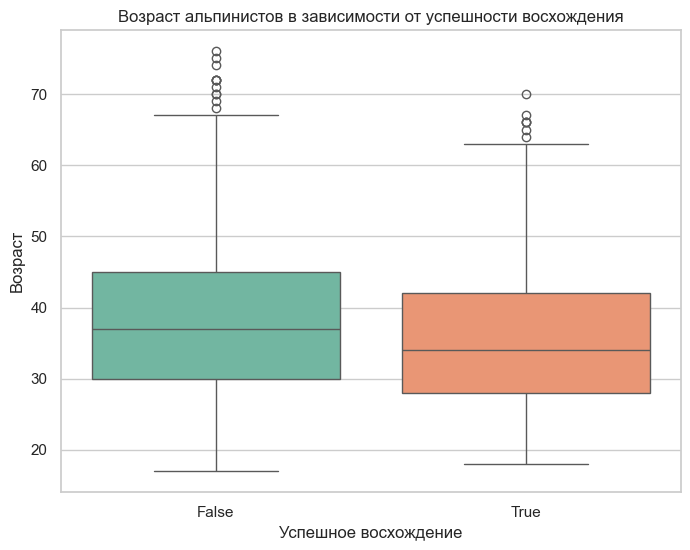

In [9]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="success", y="age", data=df, palette="Set2")
plt.title("Возраст альпинистов в зависимости от успешности восхождения")
plt.xlabel("Успешное восхождение")
plt.ylabel("Возраст")
plt.show()

In [10]:
df.groupby("success")["age"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
success,,,,,,,,
False,1269.0,37.94,10.72,17.0,30.0,37.0,45.0,76.0
True,807.0,35.41,9.80,18.0,28.0,34.0,42.0,70.0


**Вывод по п.3:** Распределения возраста для успешных и неуспешных восхождений похожи: медианы близки (~36 лет). Успешные восхождения имеют чуть более узкий межквартильный размах и меньше выбросов в области пожилого возраста. Возраст сам по себе — слабый разделитель успеха.

## 4. Матрица корреляций

In [11]:
# Приведём булевы признаки к числу и добавим age
corr_df = df.copy()
bool_cols = ["success", "solo", "oxygen_used", "died", "injured", "hired"]
for c in bool_cols:
    corr_df[c] = corr_df[c].astype(int)

corr_cols = ["age", "highpoint_metres", "count", "height_metres", "success", "solo", "oxygen_used", "died", "injured", "hired"]
corr = corr_df[corr_cols].corr(numeric_only=True)
corr.round(2)

,age,highpoint_metres,count,height_metres,success,solo,oxygen_used,died,injured,hired
age,1.00,-0.16,-0.01,-0.03,-0.12,-0.03,-0.08,0.03,-0.01,-0.28
highpoint_metres,-0.16,1.00,0.36,0.76,0.58,-0.01,0.83,-0.01,-0.06,0.31
count,-0.01,0.36,1.00,0.45,0.17,-0.01,0.35,-0.03,-0.07,0.27
height_metres,-0.03,0.76,0.45,1.00,0.14,-0.01,0.56,0.01,-0.02,0.25
success,-0.12,0.58,0.17,0.14,1.00,0.01,0.58,-0.06,-0.05,0.28
solo,-0.03,-0.01,-0.01,-0.01,0.01,1.00,0.01,-0.00,-0.00,-0.02
oxygen_used,-0.08,0.83,0.35,0.56,0.58,0.01,1.00,-0.01,-0.02,0.32
died,0.03,-0.01,-0.03,0.01,-0.06,-0.00,-0.01,1.00,-0.01,-0.02
injured,-0.01,-0.06,-0.07,-0.02,-0.05,-0.00,-0.02,-0.01,1.00,-0.06
hired,-0.28,0.31,0.27,0.25,0.28,-0.02,0.32,-0.02,-0.06,1.00


In [ ]:
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Матрица корреляций")
plt.show()

**Вывод по п.4:** Наиболее заметные связи: `highpoint_metres` положительно коррелирует с `success` и `oxygen_used`; `height_metres` (высота пика) отрицательно связан с успехом и положительно — с использованием кислорода. `count` (размер группы) положительно связан с `hired`. Корреляции в целом умеренные — сильной мультиколлинеарности между ключевыми предикторами нет.

## 5. Логистическая регрессия по удачным восхождениям

In [ ]:
# Подготовка признаков
model_df = df.copy()
model_df["sex_M"] = (model_df["sex"] == "M").astype(int)
model_df["oxygen"] = model_df["oxygen_used"].astype(int)
model_df["hired_i"] = model_df["hired"].astype(int)
model_df["solo_i"] = model_df["solo"].astype(int)
model_df["season_Spring"] = (model_df["season"] == "Spring").astype(int)
model_df["season_Autumn"] = (model_df["season"] == "Autumn").astype(int)
model_df["season_Winter"] = (model_df["season"] == "Winter").astype(int)
model_df["y"] = model_df["success"].astype(int)

features = ["age", "height_metres", "count", "sex_M", "oxygen", "hired_i", "solo_i", "season_Spring", "season_Autumn", "season_Winter"]

data = model_df[features + ["y"]].dropna()
X = data[features]
y = data["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logit = LogisticRegression(max_iter=1000)
logit.fit(X_train_s, y_train)

coefs = pd.DataFrame({"Признак": features, "Коэффициент": logit.coef_[0].round(3)})
coefs.sort_values("Коэффициент", key=abs, ascending=False)

**Вывод по п.5:** Знак и величина коэффициентов показывают направление влияния: высота пика и число участников отрицательно связаны с вероятностью успеха, а использование кислорода и наёмный статус — положительно. Возраст и пол дают слабый вклад.

## 6. ROC-кривая и AUC

In [ ]:
y_prob = logit.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая логистической регрессии")
plt.legend(loc="lower right")
plt.show()
print(f"AUC = {roc_auc:.3f}")

**Вывод по п.6:** AUC > 0.5, модель лучше случайного угадывания; чем ближе AUC к 1, тем сильнее разделяющая способность. Полученное значение отражает умеренное качество классификации.

## 7. Матрица ошибок

In [ ]:
y_pred = logit.predict(X_test_s)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Не успех", "Успех"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Матрица ошибок")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Не успех", "Успех"]))

**Вывод по п.7:** Матрица ошибок показывает число верных и неверных классификаций. Модель склонна предсказывать класс «неуспех» из-за дисбаланса классов; точность (accuracy) и полнота (recall) по классу «успех» ниже, чем по классу «неуспех».

## 8. Общие выводы

1. **Пропуски:** присутствуют в полях, связанных со смертью/травмами, а также в `highpoint_metres` и `first_ascent_year`. Для модели использовались только полные наблюдения по выбранным признакам.
2. **Описательные статистики:** средний возраст ~37 лет, средняя высота пика ~7500 м, успешность восхождений ниже 50%.
3. **Боксплот:** возраст слабо различает успешные и неуспешные восхождения — медианы почти совпадают.
4. **Корреляции:** успех положительно связан с достигнутой высшей точкой и использованием кислорода, отрицательно — с высотой пика и размером группы.
5. **Логистическая регрессия:** ключевые факторы — высота пика, размер группы, использование кислорода, наёмный статус; возраст и пол влияют слабо.
6. **ROC/AUC:** модель обладает умеренной разделяющей способностью (AUC заметно выше 0.5, но далёк от 1).
7. **Матрица ошибок:** из-за дисбаланса классов модель чаще ошибается на классе «успех»; для практики стоит рассмотреть балансировку классов, порог классификации или другие модели.

Файл с ноутбуком готов к загрузке на EOS.